<a href="https://colab.research.google.com/github/v-yunusic/REPO-PYTHON-VY/blob/main/analisis_campa%C3%B1a_banco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VIDEOS DE APOYO

* **WEBINAR - DATA SCIENCE FOR BEGINNERS:** https://www.youtube.com/watch?v=nUMO7_h7StU&t
* **Outlier detection and removal: z score, standard deviation:** https://www.youtube.com/watch?v=KFuEAGR3HS4
* **Exploratory Data Analysis (EDA) with Python & Pandas:** https://www.youtube.com/watch?v=4P4UxXK7WE8
* **Seaborn Crash Course - Data Visualization in Python:** https://www.https://www.youtube.com/watch?v=Vbe2GaWGKgkyoutube.com/watch?v=rLVCSmtoA7U&t
* **Data Cleaning with Python & Pandas:** https://www.youtube.com/watch?v=Vbe2GaWGKgk

* **Todos los modelos de Machine Learning que usa tu empresa explicados simple en 17 minutos:** https://youtu.be/XkkOyfo8gvI?si=bb-edb1vE6Hu9Hc5

* **programar es difícil, hasta que creas sistemas:** https://youtu.be/IVQ44lgC60A?si=oMa7IowHSAOr7s6X

# CONTEXTO

Un importante banco proveniente de portugal realiza una campaña mediante llamadas telefónicas con el propósito de que sus clientes contraten un deposito a plazo, sin embargo, los resultados no fueron los esperados por una gran diferencia.

El principal objetivo de este notebook es analizar los resultados de los clientes a lo largo de aproximadamente 3 años (3 periodos). Adicionalmente llegar a un posible causante de esta significativa diferencia entre quienes aceptaron y quienes no.

Finalmente se aplicará un modelo de predicción para escatimar posibles dudas.

# PIP

In [ ]:
pip install gdown

In [ ]:
pip install requests

# LIBRERIAS

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import sympy as sp
import pandas as pd
import seaborn as sns
import re # RegEx
import random #Libreria random
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import gdown
import gc

#==========API REQUESTS==========#
from google.colab import userdata
import requests
import json
#==========API REQUESTS==========#

print('Librerias importadas!\n'+'-'*60)

Librerias importadas!
------------------------------------------------------------


# DIRECTORIOS

# PREPROCESAMIENTO

In [ ]:
# Reemplaza el DataFrame pesado por uno vacío antes de borrarlo
df = pd.DataFrame()
# o simplemente:
df = None
gc.collect()

60

In [ ]:
# https://drive.google.com/file/d/1ncP38efhiQIQs1XGCJWMHLx0psRFqfof/view?usp=drive_link

try:
  if not df:
    file_id_bank = '1ncP38efhiQIQs1XGCJWMHLx0psRFqfof'
    url = f'https://drive.google.com/uc?id={file_id_bank}'

    gdown.download(url, "clientes_banco.csv", quiet=True, use_cookies=False)

    df = pd.read_csv('clientes_banco.csv', sep=';')
    print('\nDATAFRAME CARGADO!')
except:
  print(f'NO SE HA CARGADO DATAFRAME')


DATAFRAME CARGADO!


In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
print(f'Cantidad de filas:\n{df.shape[0]}')
print(f'Cantidad de columnas:\n{df.shape[1]}')

Cantidad de filas:
41188
Cantidad de columnas:
21


In [ ]:
print(f'Columnas presentes en el Dataframe:')
df.columns.tolist()

Columnas presentes en el Dataframe:


['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
# DEFINICION DE COLUMNAS NUMERICAS Y CATEGORICAS
col_categoricas = df.select_dtypes(include=['object']).columns.tolist()
col_numericas = df.select_dtypes(exclude=['object','bool']).columns.tolist()
col_bools = df.select_dtypes(include=['bool']).columns.tolist()

print(f'COLUMNAS NUMERICAS ({len(col_numericas)}):\n{col_numericas}\nCOLUMNAS CATEGORICAS ({len(col_categoricas)}):\n{col_categoricas}\nCOLUMNAS BOOLS ({len(col_bools)}):\n{col_bools}')

COLUMNAS NUMERICAS (10):
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
COLUMNAS CATEGORICAS (11):
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']
COLUMNAS BOOLS (0):
[]


In [ ]:
df[col_numericas] = df[col_numericas].apply(pd.to_numeric, errors='coerce')
df[col_numericas].describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [ ]:
for col in col_categoricas:
  valores = df[col].unique().tolist()
  print(f'{col} : {valores}\n')

job : ['housemaid', 'services', 'admin.', 'blue-collar', 'technician', 'retired', 'management', 'unemployed', 'self-employed', 'unknown', 'entrepreneur', 'student']

marital : ['married', 'single', 'divorced', 'unknown']

education : ['basic.4y', 'high.school', 'basic.6y', 'basic.9y', 'professional.course', 'unknown', 'university.degree', 'illiterate']

default : ['no', 'unknown', 'yes']

housing : ['no', 'yes', 'unknown']

loan : ['no', 'yes', 'unknown']

contact : ['telephone', 'cellular']

month : ['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'sep']

day_of_week : ['mon', 'tue', 'wed', 'thu', 'fri']

poutcome : ['nonexistent', 'failure', 'success']

y : ['no', 'yes']



In [ ]:
df[col_categoricas].describe()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


In [ ]:
print('Cantidad de valores "unknown" por columna categorica:\n')
for col in col_categoricas:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f'{col}: {unknown_count} ({unknown_count/df.shape[0]*100:.1f}%)')

Cantidad de valores "unknown" por columna categorica:

job: 330 (0.8%)
marital: 80 (0.2%)
education: 1731 (4.2%)
default: 8597 (20.9%)
housing: 990 (2.4%)
loan: 990 (2.4%)


In [ ]:
df.loc[df.duplicated()]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
20216,55,services,married,high.school,unknown,no,no,cellular,aug,mon,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
20534,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
25217,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no


In [ ]:
df = df.drop_duplicates()
df.shape[0]

41176

# ANALISIS

#### PREGUNTAS POR RESPONDER A PARTIR DE ANALISIS

* ¿Qué proporcion de clientes suscribieron o no durante la campaña?
* ¿Qué grupo etario es mas propenso a suscribir? ¿Cuál es lo contrario?
* ¿Durante cuánto tiempo se realizo dicha campaña?
* ¿Cómo influye la duracion del contacto al cliente?
* ¿Qué dia de la semana es más factible llamar?
* ¿Existe alguna relacion entre quienes han sido previamente contactados y su decision de suscribir o no?

In [ ]:
df = df.rename(columns={'age' : 'edad',
 'job' : 'trabajo',
 'marital' : 'e_civil',
 'education' : 'educacion',
 'default' : 'credito',
 'housing' : 'cred_hipotecario',
 'loan' : 'prestamo',
 'contact' : 'tipo_contacto',
 'month' : 'mes',
 'day_of_week' : 'dia_semana',
 'duration' : 'duracion',
 'campaign' : 'contactos_en_campaña',
 'pdays' : 'dias_contacto_prev',
 'previous' : 'contactos_previos',
 'poutcome' : 'resultado_anterior',
 'nr.employed' : 'num_empleados',
 'y' : 'suscribe',
 'emp.var.rate' : 'tasa.var.empleo',
 'cons.price.idx' : 'idx.precios.consumidor',
 'cons.conf.idx' : 'idx.confianza.consumidor'}, errors='raise')

In [ ]:
#CLASIFICACION DE COLUMNAS
perfil_cliente = df[[
  'edad',
  'trabajo',
  'e_civil',
  'educacion',
  'credito',
  'cred_hipotecario',
  'prestamo'
]].copy()

cols_campaña = [[
  'contactos_en_campaña',
  'dias_contacto_prev',
  'contactos_previos',
  'resultado_anterior',
  'tipo_contacto'
]].copy()

macro_cols = [[
  'tasa.var.empleo',
  'idx.precios.consumidor',
  'idx.confianza.consumidor',
  'euribor3m',
  'num_empleados'
]].copy()

periodo_cols = [[
    'mes',
    'dia_de_semana'
]].copy()

var_objetivo = df['suscribe'].copy()
col_descarte = df['duracion'].copy()

df = df.drop(columns='duracion')

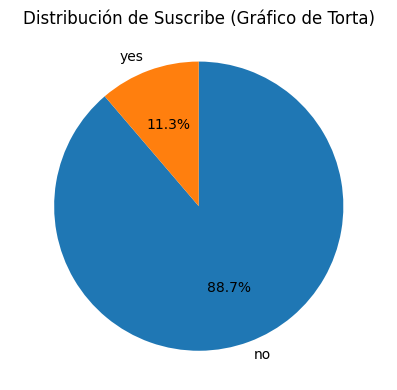

In [ ]:
# RESULTADO GENERAL CAMPAÑAS
import matplotlib.pyplot as plt
import seaborn as sns

# Define la columna para el gráfico de torta
columna = 'suscribe'

# Calcular la frecuencia de cada categoría
counts = df[columna].value_counts()

plt.figure(figsize=(8, 4))

# Gráfico de Torta
plt.subplot(1, 2, 1) # 1 fila, 2 columnas, primer gráfico
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title(f'Distribución de {columna.capitalize()} (Gráfico de Torta)')
plt.axis('equal')

plt.tight_layout()
plt.show()

/tmp/ipykernel_9426/3284240091.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


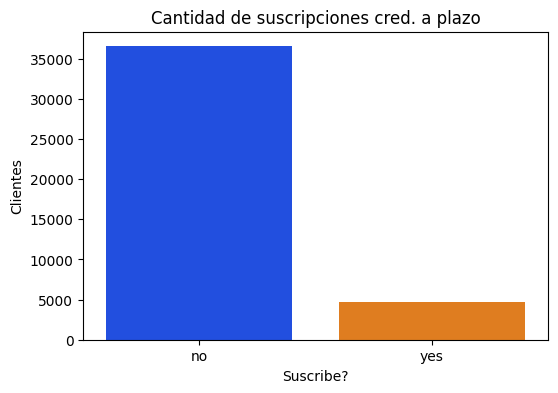

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

columna = 'suscribe'

#Para un grafico de barra, sacamos las proporcion de los datos mediante un count

plot_data = counts.reset_index()
plot_data.columns = ['Suscribe?', 'Clientes']

plt.figure(figsize=(6, 4))
sns.barplot(
    data=plot_data,
    x='Suscribe?',
    y='Clientes',
    palette='bright'
)

plt.title('Cantidad de suscripciones cred. a plazo')
plt.show()

/tmp/ipykernel_9426/4512982.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(df[columna], kde=True, bins=20, palette='bright')


<Axes: xlabel='edad', ylabel='Count'>

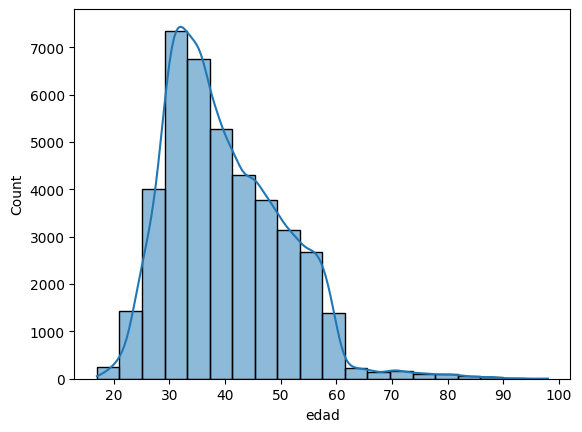

In [ ]:
columna = 'edad'

sns.histplot(df[columna], kde=True, bins=20, palette='bright')